# Gaussian Naive Bayes – Hotel Booking Cancellation Prediction

**Assignment model 4 of 5**

This notebook implements Gaussian Naive Bayes using the same cleaned training and held-out test partitions as the other classifiers.

- **Target:** `is_canceled` (`1` = cancelled; `0` = not cancelled)
- **Split:** common stratified 80:20 split, `random_state=42`
- **Classifier:** `GaussianNB` with `var_smoothing` selected on a training-only validation slice
- **Preprocessing:** median imputation and standard scaling for numerical columns; `Unknown` imputation and one-hot encoding for categorical columns
- **Evaluation:** Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC)

Run `notebooks/01_data_preparation.ipynb` first. This notebook does **not** create a new split. All learned preprocessing is fitted on training data only.

**Why Gaussian Naive Bayes?** The predictors contain continuous numerical measurements and categorical variables. One-hot encoding converts categorical variables into binary indicator features, allowing a single GaussianNB pipeline to be applied to the mixed feature set. This is an approximation: GaussianNB models each transformed feature with a Gaussian class-conditional distribution, including the 0/1 indicators. We document this limitation rather than treating the model as a perfect distributional match.

The model notebook selects the variance-smoothing setting and a cancellation-probability threshold using only an internal validation split from the training partition. The final pipeline is refitted on all training rows; the test partition is reserved for the final metrics.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

RANDOM_STATE = 42
TARGET = "is_canceled"
MODEL_NAME = "Gaussian Naive Bayes"
VAR_SMOOTHING_GRID = [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 0.1, 1.0, 10.0]
THRESHOLD_CANDIDATES = np.r_[np.arange(0.05, 0.991, 0.01), 0.995, 0.999]


## 2. Load the common training and test data

In [2]:
# Locate the project root whether this notebook is run from the root or model/.
root_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(
    (candidate.resolve() for candidate in root_candidates
     if (candidate / "data" / "train_data.csv").exists()
     and (candidate / "test_data.csv").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/train_data.csv and test_data.csv. "
        "Run notebooks/01_data_preparation.ipynb first."
    )

RESULTS_DIR = REPO_ROOT / "results"
ARTIFACTS_DIR = REPO_ROOT / "model" / "artifacts"
PLOTS_DIR = RESULTS_DIR / "visualizations"
for directory in (RESULTS_DIR, ARTIFACTS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(REPO_ROOT / "data" / "train_data.csv")
test_data = pd.read_csv(REPO_ROOT / "test_data.csv")

if TARGET not in train_data.columns or TARGET not in test_data.columns:
    raise KeyError(f"Both data files must contain target column {TARGET!r}.")
if list(train_data.columns) != list(test_data.columns):
    raise ValueError("Training and test columns do not match or are in a different order.")
if set(train_data[TARGET].dropna().unique()) != {0, 1} or set(test_data[TARGET].dropna().unique()) != {0, 1}:
    raise ValueError("Expected binary target values 0 and 1 in both partitions.")

X_train = train_data.drop(columns=[TARGET]).copy()
y_train = train_data[TARGET].astype(int).copy()
X_test = test_data.drop(columns=[TARGET]).copy()
y_test = test_data[TARGET].astype(int).copy()

print(f"Project root: {REPO_ROOT}")
print(f"Training set: {X_train.shape[0]:,} rows × {X_train.shape[1]} predictors")
print(f"Test set:     {X_test.shape[0]:,} rows × {X_test.shape[1]} predictors")
print("Training target proportions (%):")
display(y_train.value_counts(normalize=True).sort_index().mul(100).round(2).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("percent"))
print("Test target proportions (%):")
display(y_test.value_counts(normalize=True).sort_index().mul(100).round(2).rename(index={0: "Not cancelled (0)", 1: "Cancelled (1)"}).to_frame("percent"))


Project root: /mnt/data/ML-Assignment-2-work-current/ML-Assignment-2
Training set: 69,916 rows × 28 predictors
Test set:     17,480 rows × 28 predictors
Training target proportions (%):


,percent
is_canceled,
Not cancelled (0),72.51
Cancelled (1),27.49


Test target proportions (%):


,percent
is_canceled,
Not cancelled (0),72.51
Cancelled (1),27.49


## 3. Build the preprocessing and Gaussian Naive Bayes pipeline

GaussianNB requires a dense input matrix. One-hot encoding is therefore configured to produce dense `float32` output; the expected matrix size is manageable for this dataset. Numeric values are imputed with the training median and standardized. Categorical values are imputed with `Unknown` and one-hot encoded. Every preprocessing step is inside the pipeline and is fitted only when `model_pipeline.fit(X_train, y_train)` is called.

Unlike Logistic Regression and the Decision Tree, GaussianNB does not expose a `class_weight` parameter. We retain the class priors estimated from the training partition (`priors=None`) and interpret recall and precision together.

**Model selection without test leakage:** a stratified validation slice is taken only from `train_data.csv`. Candidate `var_smoothing` values and the decision threshold are selected using validation MCC (with AUC and F1 as tie-breakers). The final pipeline is then refitted on the full training partition. The held-out `test_data.csv` remains untouched until final evaluation.

In [3]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

if not numeric_features and not categorical_features:
    raise ValueError("No usable predictors were found.")

# Cast scaled numeric values to float32 to keep the dense matrix memory-efficient.
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("to_float32", FunctionTransformer(np.asarray, kw_args={"dtype": np.float32}, feature_names_out="one-to-one")),
])

# Dense one-hot output is required by GaussianNB. Handle unseen test categories safely.
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
except TypeError:  # Compatibility with older scikit-learn releases.
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False, dtype=np.float32)

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", onehot),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=0.0,
)

classifier = GaussianNB(priors=None)  # Final tuned classifier is created in the model-selection cell below.
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier),
])

print(f"Numerical features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("GaussianNB configuration:")
print(classifier)


Numerical features (17): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical features (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']
GaussianNB configuration:
GaussianNB()


## 4. Train the model

In [4]:
# Tune GaussianNB smoothing and the classification threshold on a validation slice
# taken exclusively from the training partition. The external held-out test set is
# not used for model selection.
X_tune_train, X_validation, y_tune_train, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

validation_search_rows = []
tuning_start = time.time()
for smoothing in VAR_SMOOTHING_GRID:
    tuning_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", GaussianNB(var_smoothing=smoothing, priors=None)),
    ])
    tuning_pipeline.fit(X_tune_train, y_tune_train)
    validation_probability = tuning_pipeline.predict_proba(X_validation)[:, 1]
    validation_auc = roc_auc_score(y_validation, validation_probability)

    for threshold in THRESHOLD_CANDIDATES:
        validation_prediction = (validation_probability >= threshold).astype(int)
        validation_search_rows.append({
            "var_smoothing": float(smoothing),
            "threshold": float(threshold),
            "validation_MCC": matthews_corrcoef(y_validation, validation_prediction),
            "validation_AUC": validation_auc,
            "validation_F1": f1_score(y_validation, validation_prediction, pos_label=1, zero_division=0),
            "validation_accuracy": accuracy_score(y_validation, validation_prediction),
            "validation_precision": precision_score(y_validation, validation_prediction, pos_label=1, zero_division=0),
            "validation_recall": recall_score(y_validation, validation_prediction, pos_label=1, zero_division=0),
        })

tuning_seconds = time.time() - tuning_start
validation_search = pd.DataFrame(validation_search_rows)
validation_search = validation_search.sort_values(
    ["validation_MCC", "validation_AUC", "validation_F1"],
    ascending=False,
).reset_index(drop=True)
best_candidate = validation_search.iloc[0]
validation_search.to_csv(RESULTS_DIR / "naive_bayes_validation_tuning.csv", index=False, float_format="%.6f")
BEST_VAR_SMOOTHING = float(best_candidate["var_smoothing"])
DECISION_THRESHOLD = float(best_candidate["threshold"])
display(validation_search.head(10).round(4))
print(f"Selected var_smoothing: {BEST_VAR_SMOOTHING:g}")
print(f"Selected decision threshold: {DECISION_THRESHOLD:.3f}")
print(f"Best internal-validation MCC: {best_candidate['validation_MCC']:.4f}")
print(f"Model-selection time: {tuning_seconds:.2f} seconds")

# Refit the selected pipeline on the complete official training partition only.
model_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GaussianNB(var_smoothing=BEST_VAR_SMOOTHING, priors=None)),
])
start_time = time.time()
model_pipeline.fit(X_train, y_train)
training_seconds = time.time() - start_time

transformed_sample = model_pipeline.named_steps["preprocessor"].transform(X_train.iloc[:100])
transformed_shape = model_pipeline.named_steps["preprocessor"].transform(X_train.iloc[:1]).shape
print(f"Final model refit completed in {training_seconds:.2f} seconds.")
print(f"Transformed feature count: {transformed_shape[1]:,}")
print(f"Transformed dtype: {transformed_sample.dtype}; dense matrix sample shape: {transformed_sample.shape}")
print(f"Approximate full training matrix size (float32): {len(X_train) * transformed_shape[1] * 4 / (1024**2):.1f} MiB")

,var_smoothing,threshold,validation_MCC,validation_AUC,validation_F1,validation_accuracy,validation_precision,validation_recall
0,0.10,0.970,0.3932,0.7709,0.5785,0.7271,0.5027,0.6813
1,0.10,0.980,0.3892,0.7709,0.5679,0.7436,0.5291,0.6129
2,0.10,0.960,0.3876,0.7709,0.5777,0.7102,0.4819,0.7211
3,0.10,0.950,0.3798,0.7709,0.5738,0.6957,0.4665,0.7453
4,0.10,0.940,0.3710,0.7709,0.5688,0.6833,0.4545,0.7599
5,0.01,0.999,0.3708,0.7611,0.5681,0.6936,0.4637,0.7331
6,1.00,0.480,0.3689,0.7577,0.5656,0.7026,0.4725,0.7045
7,1.00,0.490,0.3649,0.7577,0.5612,0.7097,0.4800,0.6753
8,1.00,0.470,0.3638,0.7577,0.5637,0.6910,0.4606,0.7261
9,0.10,0.930,0.3635,0.7709,0.5644,0.6721,0.4445,0.7729


Selected var_smoothing: 0.1
Selected decision threshold: 0.970
Best internal-validation MCC: 0.3932
Model-selection time: 9.72 seconds


Final model refit completed in 0.48 seconds.
Transformed feature count: 570
Transformed dtype: float32; dense matrix sample shape: (100, 570)
Approximate full training matrix size (float32): 152.0 MiB


## 5. Evaluate on the held-out test set

In [5]:
# Obtain training diagnostics and final metrics on the untouched held-out test set.
y_probability_train = model_pipeline.predict_proba(X_train)[:, 1]
y_probability = model_pipeline.predict_proba(X_test)[:, 1]
y_pred_train = (y_probability_train >= DECISION_THRESHOLD).astype(int)
y_pred = (y_probability >= DECISION_THRESHOLD).astype(int)

# The assignment's six required metrics. Cancelled bookings (class 1) are positive.
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "AUC": roc_auc_score(y_test, y_probability),
    "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred),
}
train_metrics = {
    "Accuracy": accuracy_score(y_train, y_pred_train),
    "AUC": roc_auc_score(y_train, y_probability_train),
    "Precision": precision_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "Recall": recall_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "F1": f1_score(y_train, y_pred_train, pos_label=1, zero_division=0),
    "MCC": matthews_corrcoef(y_train, y_pred_train),
}

metric_table = pd.DataFrame({
    "Metric": list(test_metrics),
    "Training": list(train_metrics.values()),
    "Test": list(test_metrics.values()),
})
metric_table[["Training", "Test"]] = metric_table[["Training", "Test"]].astype(float).round(4)
display(metric_table)

# Update one shared comparison row per model; preserve results from prior notebooks.
comparison_path = RESULTS_DIR / "model_comparison.csv"
new_row = pd.DataFrame([{"Model": MODEL_NAME, **test_metrics}])
if comparison_path.exists():
    existing = pd.read_csv(comparison_path)
    if "Model" in existing.columns:
        existing = existing[existing["Model"] != MODEL_NAME]
        comparison = pd.concat([existing, new_row], ignore_index=True)
    else:
        comparison = new_row
else:
    comparison = new_row
comparison.to_csv(comparison_path, index=False, float_format="%.6f")

pd.DataFrame([
    {"Dataset": "Train", **train_metrics},
    {"Dataset": "Test", **test_metrics},
]).to_csv(RESULTS_DIR / "naive_bayes_metrics.csv", index=False, float_format="%.6f")
pd.DataFrame({
    "actual_is_canceled": y_test.to_numpy(),
    "predicted_is_canceled": y_pred,
    "predicted_probability_cancelled": y_probability,
}).to_csv(RESULTS_DIR / "naive_bayes_test_predictions.csv", index=False)

print(f"Comparison results saved to: {comparison_path.relative_to(REPO_ROOT)}")
print(f"All final test predictions use the threshold selected from the training-only validation split: {DECISION_THRESHOLD:.3f}.")
print("Test classification report:")
print(classification_report(y_test, y_pred, target_names=["Not cancelled (0)", "Cancelled (1)"], zero_division=0, digits=4))


,Metric,Training,Test
0,Accuracy,0.7226,0.7165
1,AUC,0.7770,0.7697
2,Precision,0.4968,0.4890
3,Recall,0.7059,0.6957
4,F1,0.5832,0.5743
5,MCC,0.3979,0.3844


Comparison results saved to: results/model_comparison.csv
All final test predictions use the threshold selected from the training-only validation split: 0.970.
Test classification report:
                   precision    recall  f1-score   support

Not cancelled (0)     0.8626    0.7244    0.7875     12675
    Cancelled (1)     0.4890    0.6957    0.5743      4805

         accuracy                         0.7165     17480
        macro avg     0.6758    0.7101    0.6809     17480
     weighted avg     0.7599    0.7165    0.7289     17480



## 6. Confusion matrix and ROC curve

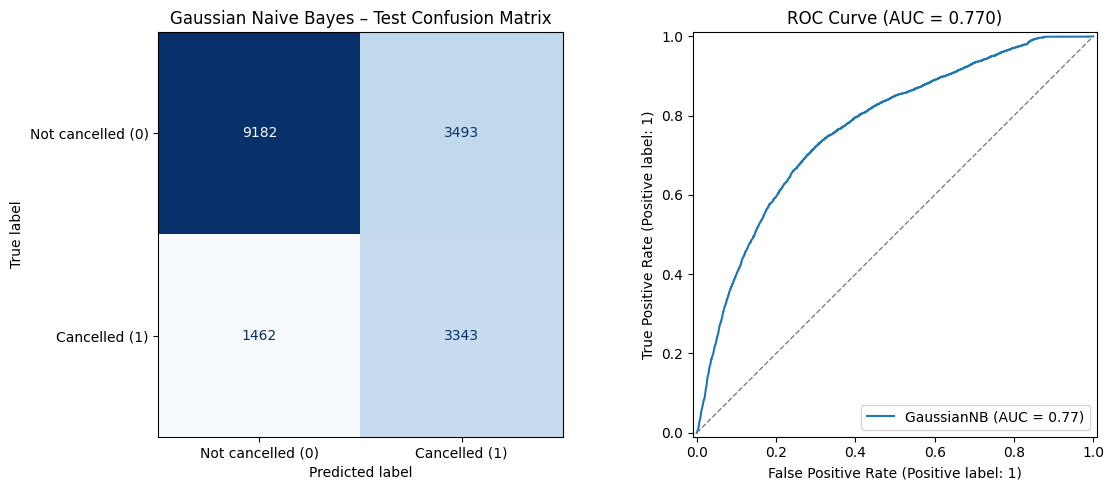

Saved: results/visualizations/naive_bayes_confusion_matrix_roc.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not cancelled (0)", "Cancelled (1)"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Gaussian Naive Bayes – Test Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[1], name="GaussianNB")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[1].set_title(f"ROC Curve (AUC = {test_metrics['AUC']:.3f})")
plt.tight_layout()
confusion_roc_path = PLOTS_DIR / "naive_bayes_confusion_matrix_roc.png"
plt.savefig(confusion_roc_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_roc_path.relative_to(REPO_ROOT)}")


## 7. Metric and probability visualisations

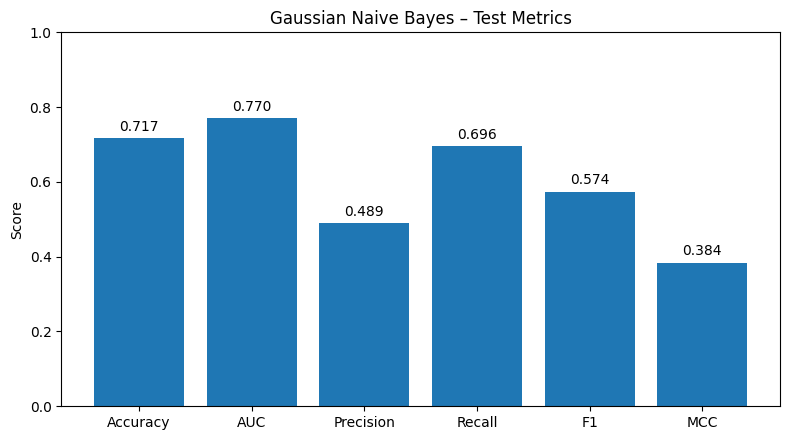

Saved: results/visualizations/naive_bayes_metrics.png


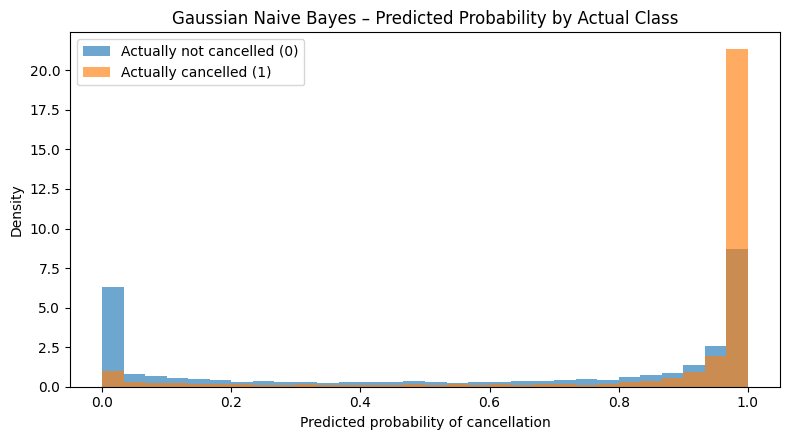

Saved: results/visualizations/naive_bayes_probability_distribution.png


In [7]:
# Plot the six required test metrics for this model.
fig, ax = plt.subplots(figsize=(8, 4.5))
metric_names = list(test_metrics.keys())
metric_values = [test_metrics[name] for name in metric_names]
bars = ax.bar(metric_names, metric_values)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Gaussian Naive Bayes – Test Metrics")
ax.bar_label(bars, fmt="%.3f", padding=3)
plt.tight_layout()
metrics_plot_path = PLOTS_DIR / "naive_bayes_metrics.png"
plt.savefig(metrics_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {metrics_plot_path.relative_to(REPO_ROOT)}")

# Show how predicted cancellation probabilities vary by actual class.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(y_probability[y_test.to_numpy() == 0], bins=30, alpha=0.65, density=True, label="Actually not cancelled (0)")
ax.hist(y_probability[y_test.to_numpy() == 1], bins=30, alpha=0.65, density=True, label="Actually cancelled (1)")
ax.set_xlabel("Predicted probability of cancellation")
ax.set_ylabel("Density")
ax.set_title("Gaussian Naive Bayes – Predicted Probability by Actual Class")
ax.legend()
plt.tight_layout()
probability_plot_path = PLOTS_DIR / "naive_bayes_probability_distribution.png"
plt.savefig(probability_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {probability_plot_path.relative_to(REPO_ROOT)}")


## 8. Save the fitted pipeline and model configuration

In [8]:
# The saved pipeline contains the fitted imputer, scaler, encoder and GaussianNB classifier.
model_path = ARTIFACTS_DIR / "naive_bayes_pipeline.joblib"
joblib.dump(model_pipeline, model_path, compress=3)

model_configuration = {
    "model": MODEL_NAME,
    "target": TARGET,
    "positive_class": 1,
    "random_state": RANDOM_STATE,
    "train_test_split": "80:20 stratified; generated once in 01_data_preparation.ipynb",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessing": {
        "numeric_imputer": "median",
        "numeric_scaler": "StandardScaler",
        "numeric_output_dtype": "float32",
        "categorical_imputer": "constant: Unknown",
        "categorical_encoder": "OneHotEncoder(handle_unknown=ignore, sparse_output=False, dtype=float32)",
        "matrix_format": "dense (required by GaussianNB)",
        "fit_policy": "All learned preprocessing fitted on training data only",
    },
    "classifier": {
        "type": "GaussianNB",
        "var_smoothing": BEST_VAR_SMOOTHING,
        "candidate_var_smoothing_values": VAR_SMOOTHING_GRID,
        "decision_threshold": DECISION_THRESHOLD,
        "threshold_selection": "Maximize MCC on a stratified 20% validation slice of the training partition; AUC and F1 are tie-breakers",
        "priors": None,
        "class_prior_policy": "estimated from training data",
    },
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "training_seconds": float(training_seconds),
    "validation_model_selection_seconds": float(tuning_seconds),
    "best_validation_metrics": {
        "MCC": float(best_candidate["validation_MCC"]),
        "AUC": float(best_candidate["validation_AUC"]),
        "F1": float(best_candidate["validation_F1"]),
    },
    "interpretation_note": "GaussianNB applies Gaussian class-conditional likelihoods to standardized numeric features and 0/1 one-hot indicators; this is a modelling approximation.",
}
config_path = ARTIFACTS_DIR / "naive_bayes_config.json"
config_path.write_text(json.dumps(model_configuration, indent=2))

# Reload the saved artifact and verify it reproduces test predictions.
reloaded_pipeline = joblib.load(model_path)
reloaded_probability = reloaded_pipeline.predict_proba(X_test)[:, 1]
reloaded_predictions = (reloaded_probability >= DECISION_THRESHOLD).astype(int)
if not np.allclose(reloaded_probability, y_probability, rtol=1e-10, atol=1e-12):
    raise AssertionError("Reloaded Naive Bayes pipeline does not reproduce test probabilities.")
if not np.array_equal(reloaded_predictions, y_pred):
    raise AssertionError("Reloaded pipeline plus saved threshold does not reproduce test predictions.")

print(f"Saved fitted pipeline: {model_path.relative_to(REPO_ROOT)}")
print(f"Saved configuration: {config_path.relative_to(REPO_ROOT)}")
print("Artifact reload check: passed; predictions match the executed model.")


Saved fitted pipeline: model/artifacts/naive_bayes_pipeline.joblib
Saved configuration: model/artifacts/naive_bayes_config.json
Artifact reload check: passed; predictions match the executed model.


## 9. Evidence-based observations

In [9]:
print("Gaussian Naive Bayes – observations based on this run")
print(f"• Test accuracy: {test_metrics['Accuracy']:.4f}; test AUC: {test_metrics['AUC']:.4f}.")
print(f"• For cancelled bookings (class 1), precision: {test_metrics['Precision']:.4f}, recall: {test_metrics['Recall']:.4f}, and F1: {test_metrics['F1']:.4f}.")
print(f"• Test MCC: {test_metrics['MCC']:.4f}.")
print(f"• Selected var_smoothing: {BEST_VAR_SMOOTHING:g}; selected probability threshold: {DECISION_THRESHOLD:.3f} (chosen using training-only validation).")
accuracy_gap = train_metrics["Accuracy"] - test_metrics["Accuracy"]
auc_gap = train_metrics["AUC"] - test_metrics["AUC"]
print(f"• Train–test accuracy gap: {accuracy_gap:+.4f}; train–test AUC gap: {auc_gap:+.4f}.")
if abs(auc_gap) < 0.03 and abs(accuracy_gap) < 0.03:
    print("• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.")
elif auc_gap > 0.05 or accuracy_gap > 0.05:
    print("• Training metrics exceed test metrics noticeably; this may indicate overfitting and should be compared with the other models.")
else:
    print("• The train/test gap should be considered alongside the other models; it is not conclusive evidence of overfitting by itself.")
print("• GaussianNB estimates class priors from the training data; it does not provide a class_weight parameter.")
print("• The model threshold was chosen on an internal validation slice of the training data, not on the held-out test data.")
print("• One-hot indicators are modelled with Gaussian class-conditional distributions, an approximation that should be acknowledged when interpreting the result.")
print("• Do not declare an overall winner until Random Forest has also been evaluated on this same held-out test partition.")


Gaussian Naive Bayes – observations based on this run
• Test accuracy: 0.7165; test AUC: 0.7697.
• For cancelled bookings (class 1), precision: 0.4890, recall: 0.6957, and F1: 0.5743.
• Test MCC: 0.3844.
• Selected var_smoothing: 0.1; selected probability threshold: 0.970 (chosen using training-only validation).
• Train–test accuracy gap: +0.0061; train–test AUC gap: +0.0073.
• The train/test gaps are small in this run; there is no strong sign of a large generalisation gap from these two measures.
• GaussianNB estimates class priors from the training data; it does not provide a class_weight parameter.
• The model threshold was chosen on an internal validation slice of the training data, not on the held-out test data.
• One-hot indicators are modelled with Gaussian class-conditional distributions, an approximation that should be acknowledged when interpreting the result.
• Do not declare an overall winner until Random Forest has also been evaluated on this same held-out test partition.


## 10. Files produced

- `results/model_comparison.csv` – shared test-set metric table
- `results/naive_bayes_metrics.csv` – training and test metrics
- `results/naive_bayes_test_predictions.csv` – actual labels, predicted labels and cancellation probabilities
- `results/naive_bayes_validation_tuning.csv` – training-only smoothing / threshold candidates and validation scores
- `results/visualizations/naive_bayes_confusion_matrix_roc.png`
- `results/visualizations/naive_bayes_metrics.png`
- `results/visualizations/naive_bayes_probability_distribution.png`
- `model/artifacts/naive_bayes_pipeline.joblib` – fitted preprocessing + GaussianNB pipeline
- `model/artifacts/naive_bayes_config.json` – model configuration and test metrics

**Academic integrity:** Review and understand the model assumptions, preprocessing, metrics and results. Be prepared to explain why GaussianNB was chosen and why its treatment of one-hot features is an approximation.